<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/verlet_cromer_exact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple Pendulum solution comparison: Verlet, Cromer and Exact.

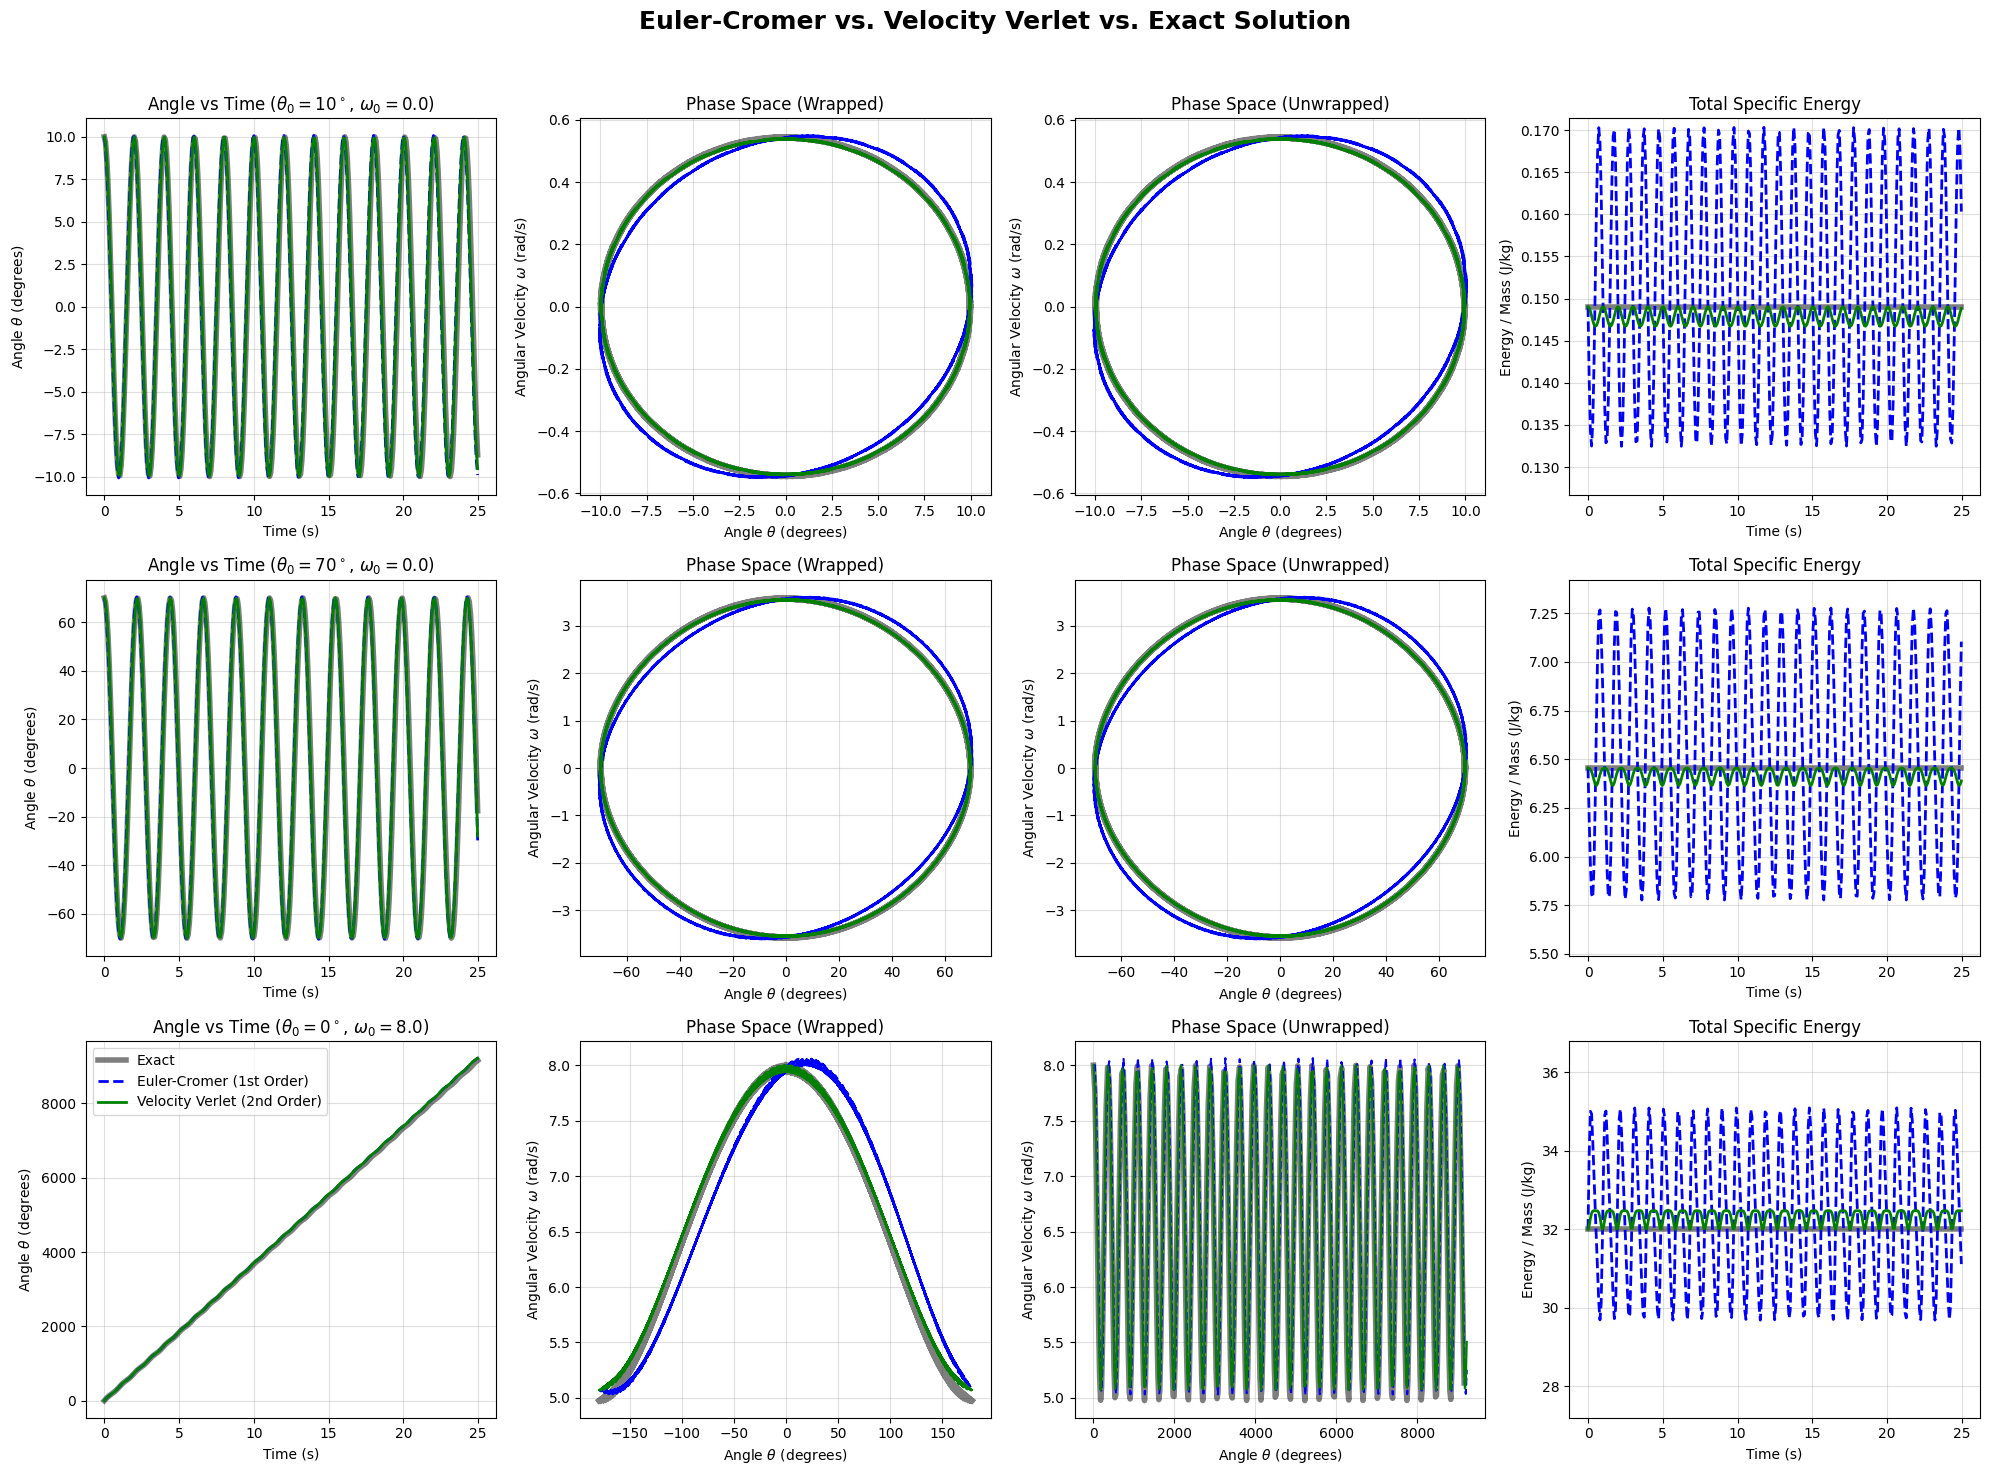

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# 1. Physical Parameters & Simulation Function
# ==========================================
g = 9.81        # Acceleration due to gravity (m/s^2)
l = 1.0         # Length of the pendulum (m)

def calc_energy(theta_rad, omega):
    """Calculates specific energy (E/m) = 1/2*(l*w)^2 + gl(1-cos(theta))"""
    return 0.5 * (l * omega)**2 + g * l * (1 - np.cos(theta_rad))

def simulate_pendulum(theta_0_deg, omega_0=0.0, dt=0.08, t_max=25.0):
    """Runs Euler-Cromer, Velocity Verlet, and Exact simulations."""
    t = np.arange(0, t_max, dt)
    n_steps = len(t)
    theta_0 = np.radians(theta_0_deg)

    # Arrays for numerical methods
    theta_cromer = np.zeros(n_steps)
    omega_cromer = np.zeros(n_steps)
    energy_cromer = np.zeros(n_steps)

    theta_verlet = np.zeros(n_steps)
    omega_verlet = np.zeros(n_steps)
    energy_verlet = np.zeros(n_steps)

    # Set initial conditions
    theta_cromer[0] = theta_0
    omega_cromer[0] = omega_0
    theta_verlet[0] = theta_0
    omega_verlet[0] = omega_0

    energy_cromer[0] = calc_energy(theta_cromer[0], omega_cromer[0])
    energy_verlet[0] = calc_energy(theta_verlet[0], omega_verlet[0])

    # ----------------------------------------------------
    # Exact Solution (using highly accurate numerical integration)
    # ----------------------------------------------------
    def exact_deriv(t, y):
        return [y[1], -(g / l) * np.sin(y[0])]

    sol = solve_ivp(exact_deriv, [0, t_max], [theta_0, omega_0], t_eval=t, rtol=1e-11, atol=1e-11)
    theta_exact = sol.y[0]
    omega_exact = sol.y[1]
    energy_exact = calc_energy(theta_exact, omega_exact)

    # ----------------------------------------------------
    # Integration Loops for Euler-Cromer and Velocity Verlet
    # ----------------------------------------------------
    # Pre-calculate the initial acceleration for Verlet
    accel = -(g / l) * np.sin(theta_verlet[0])

    for i in range(n_steps - 1):
        # Semi-Implicit Euler-Cromer (1st Order)
        omega_cromer[i+1] = omega_cromer[i] - (g / l) * np.sin(theta_cromer[i]) * dt
        theta_cromer[i+1] = theta_cromer[i] + omega_cromer[i+1] * dt
        energy_cromer[i+1] = calc_energy(theta_cromer[i+1], omega_cromer[i+1])

        # Velocity Verlet (2nd Order)
        # 1. Half-step velocity
        omega_half = omega_verlet[i] + 0.5 * accel * dt
        # 2. Full-step position
        theta_verlet[i+1] = theta_verlet[i] + omega_half * dt
        # 3. New acceleration
        accel = -(g / l) * np.sin(theta_verlet[i+1])
        # 4. Full-step velocity
        omega_verlet[i+1] = omega_half + 0.5 * accel * dt

        energy_verlet[i+1] = calc_energy(theta_verlet[i+1], omega_verlet[i+1])

    return t, (np.degrees(theta_cromer), omega_cromer, energy_cromer), \
              (np.degrees(theta_verlet), omega_verlet, energy_verlet), \
              (np.degrees(theta_exact), omega_exact, energy_exact)

# ==========================================
# 2. Run Simulations
# ==========================================
dt = 0.08       # Time step chosen to exaggerate errors
t_max = 25.0    # Duration chosen to let phase drift accumulate

# 1. Small angle swinging
res_small = simulate_pendulum(theta_0_deg=10, omega_0=0.0, dt=dt, t_max=t_max)
# 2. Large angle swinging
res_large = simulate_pendulum(theta_0_deg=70, omega_0=0.0, dt=dt, t_max=t_max)
# 3. Continuous Rotation
res_rot = simulate_pendulum(theta_0_deg=0.0, omega_0=8.0, dt=dt, t_max=t_max)

# ==========================================
# 3. Plotting the Comparison
# ==========================================
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle('Euler-Cromer vs. Velocity Verlet vs. Exact Solution', fontsize=18, weight='bold', y=0.98)

def wrap_phase(theta, omega):
    """Wraps the angle to [-180, 180] and inserts NaNs to prevent drawing lines across the plot."""
    theta_wrapped = (theta + 180) % 360 - 180
    jumps = np.abs(np.diff(theta_wrapped)) > 180
    jump_idx = np.where(jumps)[0] + 1
    theta_plot = np.insert(theta_wrapped, jump_idx, np.nan)
    omega_plot = np.insert(omega, jump_idx, np.nan)
    return theta_plot, omega_plot

def plot_row(ax_row, t, cromer, verlet, exact, th0, om0):
    """Helper function to plot a single row of 4 charts."""
    ax1, ax2, ax3, ax4 = ax_row
    tc, oc, ec = cromer
    tv, ov, ev = verlet
    tx, ox, ex = exact

    title_params = f'$\\theta_0 = {th0}^\\circ$, $\\omega_0 = {om0}$'

    # --- Plot 1: Angle vs Time ---
    ax1.plot(t, tx, 'k-', linewidth=4, alpha=0.5, label='Exact')
    ax1.plot(t, tc, 'b--', linewidth=2, label='Euler-Cromer (1st Order)')
    ax1.plot(t, tv, 'g-', linewidth=2, label='Velocity Verlet (2nd Order)')
    ax1.set_title(f'Angle vs Time ({title_params})', fontsize=12)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Angle $\\theta$ (degrees)')
    ax1.grid(True, alpha=0.4)
    if ax_row[0] == axes[2, 0]:
        ax1.legend(loc='upper left')

    # --- Plot 2: Phase Space (Wrapped) ---
    tx_w, ox_w = wrap_phase(tx, ox)
    tc_w, oc_w = wrap_phase(tc, oc)
    tv_w, ov_w = wrap_phase(tv, ov)

    ax2.plot(tx_w, ox_w, 'k-', linewidth=4, alpha=0.5, label='Exact')
    ax2.plot(tc_w, oc_w, 'b--', linewidth=1.5, label='Euler-Cromer')
    ax2.plot(tv_w, ov_w, 'g-', linewidth=1.5, label='Velocity Verlet')
    ax2.set_title(f'Phase Space (Wrapped)', fontsize=12)
    ax2.set_xlabel('Angle $\\theta$ (degrees)')
    ax2.set_ylabel('Angular Velocity $\\omega$ (rad/s)')
    ax2.grid(True, alpha=0.4)

    # --- Plot 3: Phase Space (Unwrapped) ---
    ax3.plot(tx, ox, 'k-', linewidth=4, alpha=0.5, label='Exact')
    ax3.plot(tc, oc, 'b--', linewidth=1.5, label='Euler-Cromer')
    ax3.plot(tv, ov, 'g-', linewidth=1.5, label='Velocity Verlet')
    ax3.set_title(f'Phase Space (Unwrapped)', fontsize=12)
    ax3.set_xlabel('Angle $\\theta$ (degrees)')
    ax3.set_ylabel('Angular Velocity $\\omega$ (rad/s)')
    ax3.grid(True, alpha=0.4)

    # --- Plot 4: Total Energy over Time ---
    ax4.plot(t, ex, 'k-', linewidth=4, alpha=0.5, label='Exact')
    ax4.plot(t, ec, 'b--', linewidth=2, label='Euler-Cromer')
    ax4.plot(t, ev, 'g-', linewidth=2, label='Velocity Verlet')
    ax4.set_title(f'Total Specific Energy', fontsize=12)
    ax4.set_xlabel('Time (s)')
    ax4.set_ylabel('Energy / Mass (J/kg)')

    # Zoom in on the energy to see the wobble magnitude difference!
    e_mean = np.mean(ex)
    e_range = e_mean * 0.15 if e_mean > 0 else 0.5
    ax4.set_ylim(e_mean - e_range, e_mean + e_range)
    ax4.grid(True, alpha=0.4)

# Plot all cases
plot_row(axes[0], res_small[0], res_small[1], res_small[2], res_small[3], 10, 0.0)
plot_row(axes[1], res_large[0], res_large[1], res_large[2], res_large[3], 70, 0.0)
plot_row(axes[2], res_rot[0], res_rot[1], res_rot[2], res_rot[3], 0, 8.0)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()